In [1]:
!pip -q install mlflow scikit-learn pandas numpy matplotlib seaborn

from pathlib import Path

BASE = Path("/content/Actividad5")

for folder in ["datos", "fuentes", "evidencias", "mlruns"]:
    (BASE / folder).mkdir(parents=True, exist_ok=True)

print("Environment and project folders ready!")

Environment and project folders ready!


In [3]:
import pandas as pd
import numpy as np
import hashlib
from sklearn.datasets import load_breast_cancer

# 1. Load public dataset
dataset = load_breast_cancer(as_frame=True)
df_original = dataset.frame.copy()
df_original = df_original.rename(
    columns={"target": "target_original"}
)

# 2. Data quality checks
print("Original shape:", df_original.shape)
print("Missing values:", df_original.isnull().sum().sum())
print("Duplicate rows:", df_original.duplicated().sum())

# 3. Clean the dataset
df_clean = df_original.drop_duplicates().copy()
df_clean.columns = [
    col.strip().lower().replace(" ", "_")
    for col in df_clean.columns
]

# Positive class = malignant (1)
# Original sklearn coding: 0 = malignant, 1 = benign
df_clean["target_maligno"] = (
    df_clean.pop("target_original") == 0
).astype(int)

# 4. Validate
assert df_clean.isnull().sum().sum() == 0
assert df_clean["target_maligno"].isin([0, 1]).all()

# 5. Save versioned datasets
original_dir = BASE / "datos" / "datos_org"
clean_dir = BASE / "datos" / "datos_limp"

original_dir.mkdir(parents=True, exist_ok=True)
clean_dir.mkdir(parents=True, exist_ok=True)

original_path = original_dir / "wdbc_original_v1.csv"
clean_path = clean_dir / "wdbc_clean_v1.csv"

df_original.to_csv(original_path, index=False)
df_clean.to_csv(clean_path, index=False)

# 6. SHA-256 checksums for traceability
for path in [original_path, clean_path]:
    file_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    print(f"{path.name} | SHA256: {file_hash[:16]}...")

print("\nCleaned shape:", df_clean.shape)
print("\nClass distribution:")
print(df_clean["target_maligno"].value_counts())
print("\nDataset preparation completed!")


Original shape: (569, 31)
Missing values: 0
Duplicate rows: 0
wdbc_original_v1.csv | SHA256: 0dd56a691f0a76b4...
wdbc_clean_v1.csv | SHA256: e096882d29158a1d...

Cleaned shape: (569, 31)

Class distribution:
target_maligno
0    357
1    212
Name: count, dtype: int64

Dataset preparation completed!


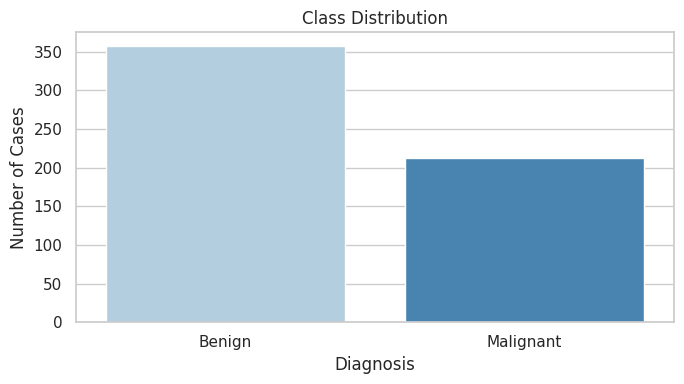

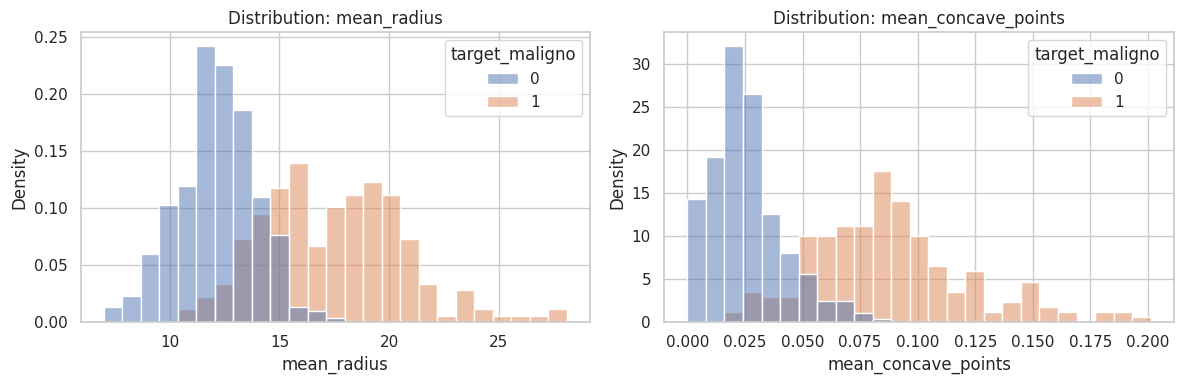

Top 5 features with potential outliers:
area_error          65
radius_error        38
perimeter_error     38
worst_area          35
smoothness_error    30
dtype: int64

EDA completed. Figures saved!


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Figure 1: Class distribution
plt.figure(figsize=(7, 4))

ax = sns.countplot(
    data=df_clean,
    x="target_maligno",
    hue="target_maligno",
    palette="Blues",
    legend=False
)

ax.set_xticks([0, 1])
ax.set_xticklabels(["Benign", "Malignant"])
plt.title("Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Cases")
plt.tight_layout()
plt.savefig(BASE / "evidencias" / "class_distribution.png", dpi=150)
plt.show()

# Figure 2: Feature distributions
features = ["mean_radius", "mean_concave_points"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, feature in zip(axes, features):
    sns.histplot(
        data=df_clean,
        x=feature,
        hue="target_maligno",
        bins=25,
        stat="density",
        common_norm=False,
        alpha=0.5,
        ax=ax
    )
    ax.set_title(f"Distribution: {feature}")

plt.tight_layout()
plt.savefig(BASE / "evidencias" / "feature_distributions.png", dpi=150)
plt.show()

# Outlier exploration using IQR
X_numeric = df_clean.drop(columns=["target_maligno"])
Q1 = X_numeric.quantile(0.25)
Q3 = X_numeric.quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (X_numeric < Q1 - 1.5 * IQR) |
    (X_numeric > Q3 + 1.5 * IQR)
).sum().sort_values(ascending=False)

print("Top 5 features with potential outliers:")
print(outliers.head())

print("\nEDA completed. Figures saved!")


In [5]:
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)

# Features and target
X = df_clean.drop(columns=["target_maligno"])
y = df_clean["target_maligno"]

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Model 1: Logistic Regression
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=3000,
        solver="liblinear",
        random_state=42
    ))
])

logistic_params = {
    "model__C": [0.1, 1, 10],
    "model__class_weight": [None, "balanced"]
}

# Model 2: Random Forest
forest_pipeline = Pipeline([
    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

forest_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 8],
    "model__min_samples_leaf": [1, 3]
}

# Hyperparameter tuning
models = {
    "Logistic Regression": (logistic_pipeline, logistic_params),
    "Random Forest": (forest_pipeline, forest_params)
}

trained_models = {}
results = []

for name, (pipeline, params) in models.items():
    print(f"\nTraining: {name}")

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=params,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    best_model = search.best_estimator_
    predictions = best_model.predict(X_test)
    probabilities = best_model.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "CV_AUC_Mean": search.best_score_,
        "CV_AUC_STD": search.cv_results_[
            "std_test_score"
        ][search.best_index_]
    }

    trained_models[name] = search
    results.append(metrics)

    print("Best parameters:", search.best_params_)
    print(classification_report(
        y_test, predictions,
        target_names=["Benign", "Malignant"]
    ))

# Comparison table
results_df = pd.DataFrame(results)
display(results_df.round(4))

# Save results for reproducibility
results_df.to_csv(
    BASE / "evidencias" / "model_comparison.csv",
    index=False
)

print("\nModel training and evaluation completed!")



Training: Logistic Regression
Best parameters: {'model__C': 1, 'model__class_weight': None}
              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98        72
   Malignant       0.98      0.95      0.96        42

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114


Training: Random Forest
Best parameters: {'model__max_depth': 8, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97        72
   Malignant       1.00      0.90      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.95      0.96       114
weighted avg       0.97      0.96      0.96       114



,Model,Accuracy,Precision,Recall,F1,ROC_AUC,CV_AUC_Mean,CV_AUC_STD
0,Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.996,0.9959,0.0046
1,Random Forest,0.9649,1.0000,0.9048,0.9500,0.994,0.9891,0.0067



Model training and evaluation completed!


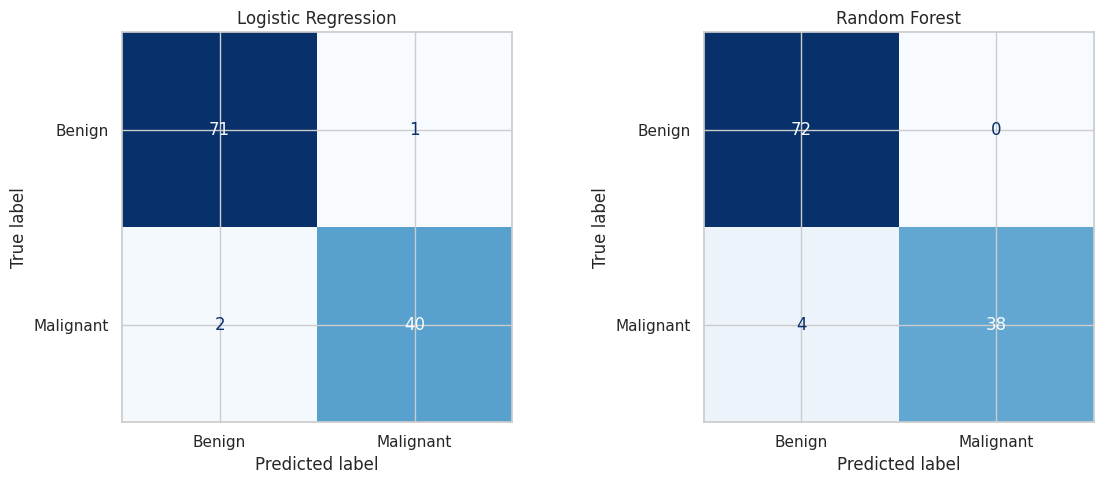

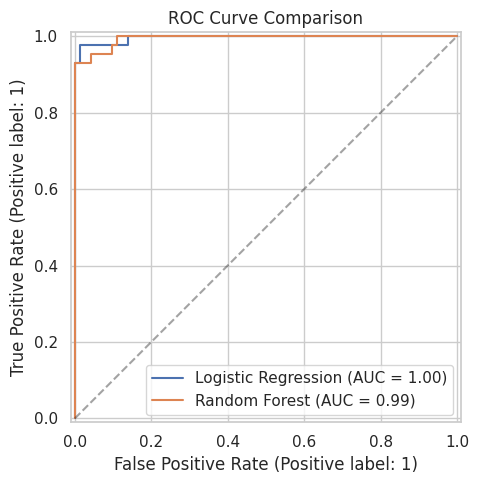

Comparison figures saved successfully!


In [6]:
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay
)
import matplotlib.pyplot as plt

# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, search) in zip(
    axes, trained_models.items()
):
    ConfusionMatrixDisplay.from_estimator(
        search.best_estimator_,
        X_test,
        y_test,
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.savefig(
    BASE / "evidencias" / "confusion_matrices.png",
    dpi=150
)
plt.show()

# ROC comparison
fig, ax = plt.subplots(figsize=(7, 5))

for name, search in trained_models.items():
    RocCurveDisplay.from_estimator(
        search.best_estimator_,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("ROC Curve Comparison")
plt.tight_layout()
plt.savefig(
    BASE / "evidencias" / "roc_comparison.png",
    dpi=150
)
plt.show()

print("Comparison figures saved successfully!")


In [12]:
import mlflow
import mlflow.sklearn
import hashlib
from mlflow.models import infer_signature

# Tracking configuration
DB_PATH = BASE / "mlflow.db"
ARTIFACT_DIR = BASE / "mlartifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)

mlflow.set_tracking_uri(f"sqlite:///{DB_PATH}")

experiment_name = "Actividad5_Comparacion_Modelos"

if mlflow.get_experiment_by_name(experiment_name) is None:
    mlflow.create_experiment(
        experiment_name,
        artifact_location=ARTIFACT_DIR.resolve().as_uri()
    )

mlflow.set_experiment(experiment_name)

# Dataset fingerprint
dataset_hash = hashlib.sha256(
    clean_path.read_bytes()
).hexdigest()

# Record experiments
for row in results:
    name = row["Model"]
    search = trained_models[name]
    best_model = search.best_estimator_

    with mlflow.start_run(run_name=name) as run:

        # Parameters
        mlflow.log_params(search.best_params_)
        mlflow.log_param("cv_folds", 5)
        mlflow.log_param("test_size", 0.20)
        mlflow.log_param("random_state", 42)
        mlflow.log_param("dataset_sha256", dataset_hash)

        # Metrics
        for metric in [
            "Accuracy", "Precision", "Recall",
            "F1", "ROC_AUC",
            "CV_AUC_Mean", "CV_AUC_STD"
        ]:
            mlflow.log_metric(
                metric.lower(),
                float(row[metric])
            )

        # Metadata
        mlflow.set_tags({
            "project": "Actividad 5",
            "dataset": "Wisconsin Breast Cancer",
            "positive_class": "Malignant",
            "selection_metric": "ROC-AUC",
            "data_version": "v1"
        })

        # Visual evidence
        mlflow.log_artifacts(
            str(BASE / "evidencias"),
            artifact_path="evidencias"
        )

        # Save trained model with input schema
        signature = infer_signature(
            X_train.head(5),
            best_model.predict(X_train.head(5))
        )

        model_info = mlflow.sklearn.log_model(
            sk_model=best_model,
            name=name.lower().replace(" ", "_"),
            signature=signature,
            input_example=X_train.head(5),
            serialization_format="skops",
            skops_trusted_types=[
                "sklearn.tree._tree.Tree"
            ]
        )

        print(f"Registered: {name}")
        print(f"Run ID: {run.info.run_id}")
        print(f"Model URI: {model_info.model_uri}")

print("\nMLflow experiment registration complete!")


Registered: Logistic Regression
Run ID: 0a7c247d401b4d1ea5be27ba79714832
Model URI: models:/m-5bde8415358b498388af3b58c2548485
Registered: Random Forest
Run ID: 1b73258958c049db907f02ffe311898e
Model URI: models:/m-edd7897589cb4b8cbee050567e79c1ec

MLflow experiment registration complete!


In [13]:
from mlflow.tracking import MlflowClient
from mlflow.models import infer_signature

client = MlflowClient()

experiment = mlflow.get_experiment_by_name(
    experiment_name
)

# Locate the interrupted Random Forest run
rf_runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="tags.mlflow.runName = 'Random Forest'",
    max_results=1,
    order_by=["attributes.start_time DESC"]
)

assert rf_runs, "Random Forest run not found"

rf_run_id = rf_runs[0].info.run_id

# Recover the previously trained model
rf_model = trained_models[
    "Random Forest"
].best_estimator_

signature = infer_signature(
    X_train.head(5),
    rf_model.predict(X_train.head(5))
)

# Resume the original run instead of creating another
with mlflow.start_run(run_id=rf_run_id):

    model_info = mlflow.sklearn.log_model(
        sk_model=rf_model,
        name="random_forest",
        signature=signature,
        input_example=X_train.head(5),
        serialization_format="skops",
        skops_trusted_types=[
            "sklearn.tree._tree.Tree"
        ]
    )

    print("Random Forest model saved!")
    print("Run ID:", rf_run_id)
    print("Model URI:", model_info.model_uri)

print("\nMLflow recovery completed successfully!")


Random Forest model saved!
Run ID: 1b73258958c049db907f02ffe311898e
Model URI: models:/m-db6de6501eb44378a0a2a4e103b73c51

MLflow recovery completed successfully!


In [14]:

# Retrieve experiment runs
experiment = mlflow.get_experiment_by_name(
    experiment_name
)

runs_df = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

columns = [
    "tags.mlflow.runName",
    "metrics.accuracy",
    "metrics.precision",
    "metrics.recall",
    "metrics.f1",
    "metrics.roc_auc",
    "metrics.cv_auc_mean"
]

display(runs_df[columns].round(4))

print("Registered runs:", len(runs_df))
print("MLflow version:", mlflow.__version__)
print("Tracking database:", DB_PATH)

assert len(runs_df) >= 2, "Expected at least two runs"
print("MLflow verification successful!")

,tags.mlflow.runName,metrics.accuracy,metrics.precision,metrics.recall,metrics.f1,metrics.roc_auc,metrics.cv_auc_mean
0,Random Forest,0.9649,1.0000,0.9048,0.9500,0.994,0.9891
1,Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.996,0.9959
2,Random Forest,0.9649,1.0000,0.9048,0.9500,0.994,0.9891
3,Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.996,0.9959
4,Random Forest,0.9649,1.0000,0.9048,0.9500,0.994,0.9891
5,Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.996,0.9959


Registered runs: 6
MLflow version: 3.17.2
Tracking database: /content/Actividad5/mlflow.db
MLflow verification successful!


In [15]:
import subprocess
import time
from google.colab import output

log_path = BASE / "mlflow_server.log"

server_log = open(log_path, "a")

server = subprocess.Popen(
    [
        "mlflow", "server",
        "--backend-store-uri", f"sqlite:///{DB_PATH}",
        "--host", "127.0.0.1",
        "--port", "5000"
    ],
    stdout=server_log,
    stderr=subprocess.STDOUT
)

time.sleep(5)

if server.poll() is None:
    print("Opening MLflow dashboard...")
    output.serve_kernel_port_as_window(5000)
else:
    print("Server could not start.")
    print(log_path.read_text()[-2500:])


Opening MLflow dashboard...
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [17]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

experiment = mlflow.get_experiment_by_name(
    experiment_name
)

all_runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["attributes.start_time DESC"]
)

# Retain the latest run for each model
retained_models = set()

for run in all_runs:
    model_name = run.data.tags.get("mlflow.runName")

    if model_name not in retained_models:
        retained_models.add(model_name)
        print("Keeping:", model_name, run.info.run_id)
    else:
        client.delete_run(run.info.run_id)
        print("Archived duplicate:", model_name)

print("\nActive experiment runs:")
display(
    mlflow.search_runs(
        experiment_ids=[experiment.experiment_id]
    )[[
        "tags.mlflow.runName",
        "metrics.accuracy",
        "metrics.recall",
        "metrics.roc_auc"
    ]]
)


Keeping: Random Forest 1b73258958c049db907f02ffe311898e
Keeping: Logistic Regression 0a7c247d401b4d1ea5be27ba79714832
Archived duplicate: Random Forest
Archived duplicate: Logistic Regression
Archived duplicate: Random Forest
Archived duplicate: Logistic Regression

Active experiment runs:


,tags.mlflow.runName,metrics.accuracy,metrics.recall,metrics.roc_auc
0,Random Forest,0.964912,0.904762,0.994048
1,Logistic Regression,0.973684,0.952381,0.996032


In [19]:
import subprocess
import time
from google.colab import output

PORT = 5001
log_path_fixed = BASE / "mlflow_server_fixed.log"

command = [
    "mlflow", "server",
    "--backend-store-uri", f"sqlite:///{DB_PATH}",
    "--host", "127.0.0.1",
    "--port", str(PORT),
    "--workers", "1",
    "--allowed-hosts",
    "localhost:*,127.0.0.1:*,*.googleusercontent.com,*.googleusercontent.com:*",
    "--cors-allowed-origins",
    "https://colab.research.google.com,https://*.googleusercontent.com",
    "--x-frame-options", "NONE"
]

with open(log_path_fixed, "w") as log_file:
    server_fixed = subprocess.Popen(
        command,
        stdout=log_file,
        stderr=subprocess.STDOUT
    )

time.sleep(5)

if server_fixed.poll() is None:
    print("MLflow server started on port", PORT)
    output.serve_kernel_port_as_iframe(
        PORT,
        height="700"
    )
else:
    print("Server failed:")
    print(log_path_fixed.read_text()[-3000:])


MLflow server started on port 5001


<IPython.core.display.Javascript object>

In [20]:

import pandas as pd
import shutil
from mlflow.tracking import MlflowClient
from IPython.display import display
from google.colab import files

client = MlflowClient()
experiment = mlflow.get_experiment_by_name(experiment_name)

runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    order_by=["attributes.start_time DESC"]
)

records = []
report = [
    "ACTIVIDAD 5 - EVIDENCIA DE MLFLOW",
    f"MLflow version: {mlflow.__version__}",
    f"Experiment: {experiment.name}",
    f"Experiment ID: {experiment.experiment_id}",
    "=" * 55
]

for run in runs:
    name = run.data.tags.get("mlflow.runName", "Unknown")

    records.append({
        "Model": name,
        "Run_ID": run.info.run_id,
        "Status": run.info.status,
        **run.data.metrics
    })

    report.append(f"\nMODEL: {name}")
    report.append(f"Run ID: {run.info.run_id}")
    report.append(f"Status: {run.info.status}")

    report.append("\nHYPERPARAMETERS:")
    for key, value in sorted(run.data.params.items()):
        report.append(f"  {key}: {value}")

    report.append("\nMETRICS:")
    for key, value in sorted(run.data.metrics.items()):
        report.append(f"  {key}: {value:.6f}")

    report.append("-" * 55)

evidence_df = pd.DataFrame(records)

assert len(evidence_df) == 2, "Expected two active runs"

# Save MLflow evidence
evidence_df.to_csv(
    BASE / "evidencias" / "mlflow_runs.csv",
    index=False
)

(BASE / "evidencias" / "mlflow_details.txt").write_text(
    "\n".join(report),
    encoding="utf-8"
)

print("MLFLOW EXPERIMENT EVIDENCE")
display(evidence_df.round(4))

print("\n" + "\n".join(report))

# Backup current project
backup_path = shutil.make_archive(
    "/content/Actividad5_respaldo",
    "zip",
    root_dir="/content",
    base_dir="Actividad5"
)

print("\nProject backup:", backup_path)
files.download(backup_path)


MLFLOW EXPERIMENT EVIDENCE


,Model,Run_ID,Status,accuracy,precision,recall,f1,roc_auc,cv_auc_mean,cv_auc_std
0,Random Forest,1b73258958c049db907f02ffe311898e,FINISHED,0.9649,1.0000,0.9048,0.9500,0.994,0.9891,0.0067
1,Logistic Regression,0a7c247d401b4d1ea5be27ba79714832,FINISHED,0.9737,0.9756,0.9524,0.9639,0.996,0.9959,0.0046



ACTIVIDAD 5 - EVIDENCIA DE MLFLOW
MLflow version: 3.17.2
Experiment: Actividad5_Comparacion_Modelos
Experiment ID: 1

MODEL: Random Forest
Run ID: 1b73258958c049db907f02ffe311898e
Status: FINISHED

HYPERPARAMETERS:
  cv_folds: 5
  dataset_sha256: e096882d29158a1d790a333aad4ce19cc5beb33166f18f51358b5ab6fad1b36a
  model__max_depth: 8
  model__min_samples_leaf: 1
  model__n_estimators: 200
  random_state: 42
  test_size: 0.2

METRICS:
  accuracy: 0.964912
  cv_auc_mean: 0.989112
  cv_auc_std: 0.006721
  f1: 0.950000
  precision: 1.000000
  recall: 0.904762
  roc_auc: 0.994048
-------------------------------------------------------

MODEL: Logistic Regression
Run ID: 0a7c247d401b4d1ea5be27ba79714832
Status: FINISHED

HYPERPARAMETERS:
  cv_folds: 5
  dataset_sha256: e096882d29158a1d790a333aad4ce19cc5beb33166f18f51358b5ab6fad1b36a
  model__C: 1
  model__class_weight: None
  random_state: 42
  test_size: 0.2

METRICS:
  accuracy: 0.973684
  cv_auc_mean: 0.995872
  cv_auc_std: 0.004650
  f1: 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>